# Simulation examples

This notebook shows the current simulator API in two settings:

- one episode, step by step
- many episodes, with density mean and standard deviation


## Imports


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
import scienceplots

from network_creation.core.agent import Agent
from network_creation.core.environment import Environment
from network_creation.core.model import SchedulingMode
from network_creation.core.simulator import Simulator
from network_creation.observers import (
    ActionPrintObserver,
    DensityObserver,
    StateHistoryObserver,
)
from network_creation.plotting.episode_series import \
    plot_episode_series_observer
from network_creation.plotting.ownership_history import \
    build_circle_layout, plot_ownership_history
from network_creation.policies.random import RandomPolicy


In [3]:
plt.style.use(style="science")

## Plot helpers


In [4]:
fixed_layout = build_circle_layout(n_nodes=6)


## Single episode


In [5]:
initial_ownership = np.array(
    [
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0],
    ],
    dtype=np.int8,
)

env = Environment(ownership_matrix=initial_ownership, seed=11)
fixed_layout = build_circle_layout(n_nodes=initial_ownership.shape[0])

agents = tuple(
    Agent(
        id=node_id,
        radius=2,
        policy=RandomPolicy(seed=42 + node_id),
        seed=42 + node_id,
    )
    for node_id in range(initial_ownership.shape[0])
)

mode = SchedulingMode.SEQUENTIAL
max_steps = 10
simulator_seed = 301

action_printer = ActionPrintObserver(observation_frequency=1, print_empty_steps=False)
state_history_observer = StateHistoryObserver(observation_frequency=1, keep_runs=False)

In [6]:
simulator = Simulator(
    env=env,
    agents=agents,
    mode=mode,
    max_steps=max_steps,
    rng=np.random.default_rng(simulator_seed),
    observers=(action_printer, state_history_observer),
)

simulator.run(n_episodes=1)


step 1
  0: PASS

step 2
  1: DELETE->2

step 3
  2: BRIDGE->1

step 4
  3: BRIDGE->1

step 5
  4: BRIDGE->0

step 6
  0: DELETE->1

step 7
  1: ADD->4

step 8
  2: ADD->4

step 9
  3: DELETE->4

step 10
  4: PASS


### Directed ownership graph after each sampled step


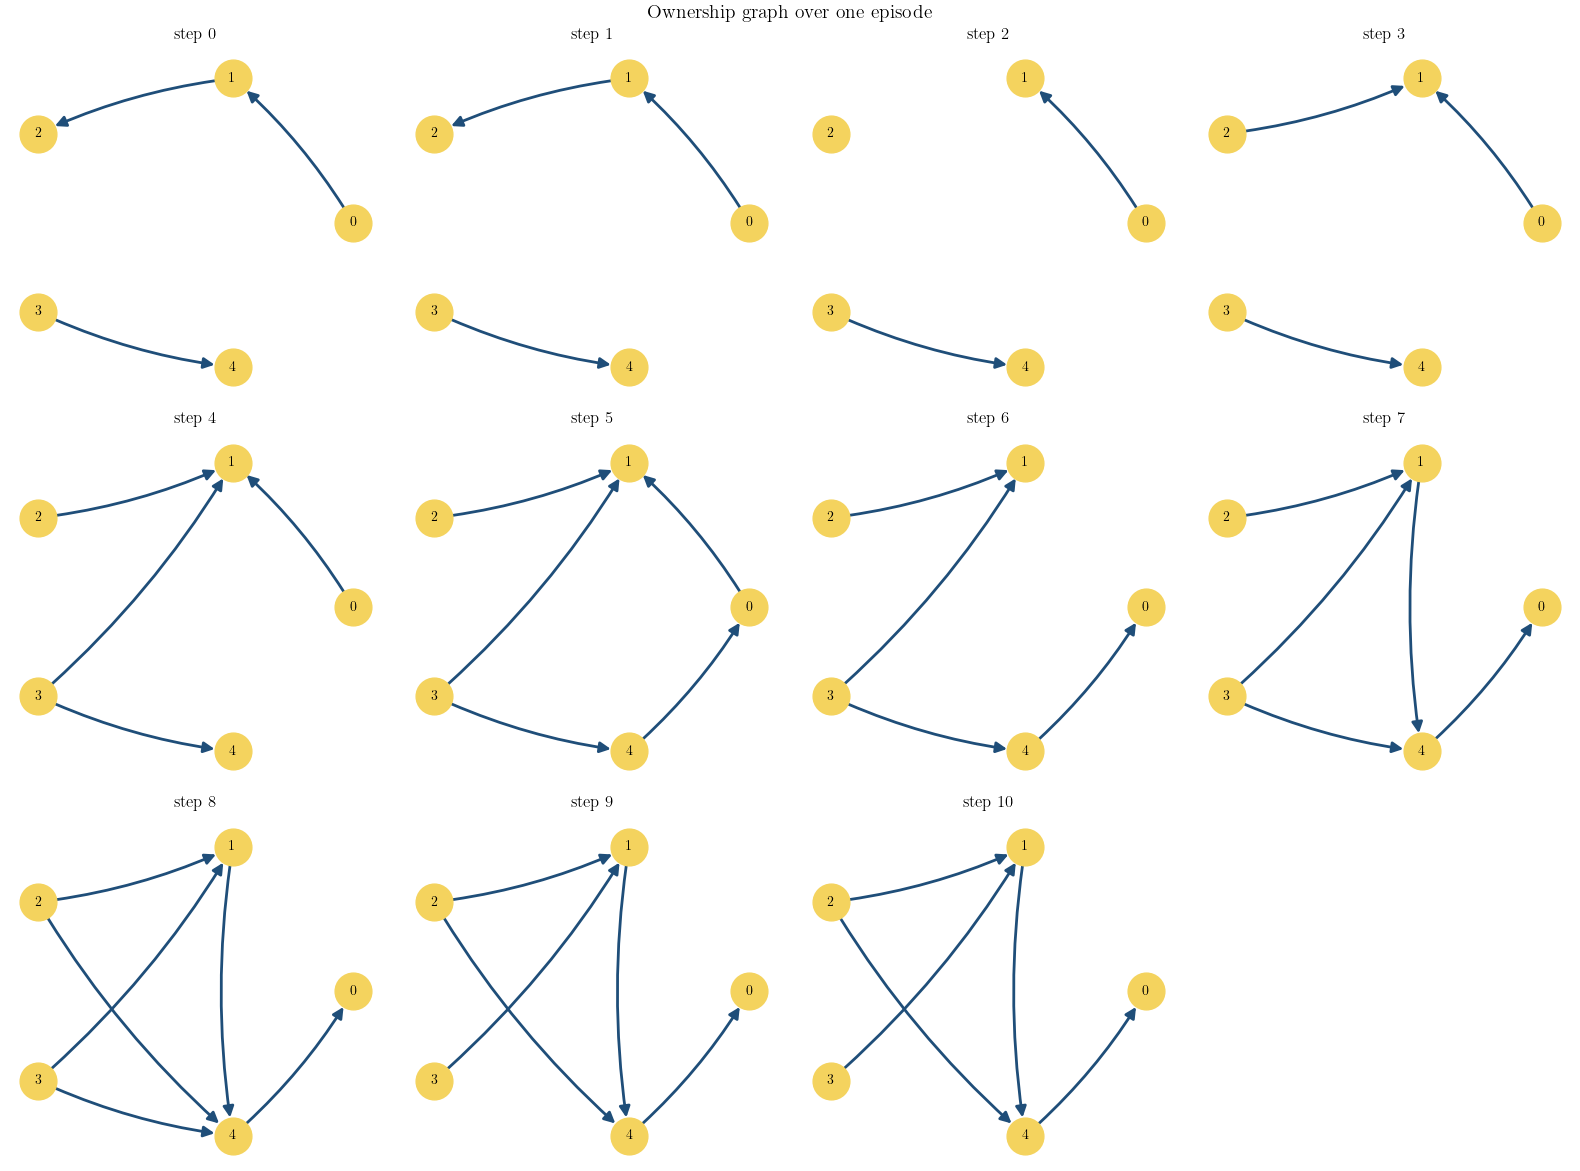

In [7]:
plot_ownership_history(
    steps=state_history_observer.steps,
    ownership_matrices=state_history_observer.ownership_matrices,
    layout=fixed_layout,
    figure_title="Ownership graph over one episode",
    max_cols=4,
)
plt.show()


## Multiple episodes

The simulator now derives a fresh seed for each agent at each episode.
That keeps repeated runs reproducible while avoiding identical random episodes.


In [8]:
multi_env = Environment(ownership_matrix=np.zeros((6, 6), dtype=np.int8), seed=101)
multi_agents = tuple(
    Agent(
        id=node_id,
        radius=2,
        policy=RandomPolicy(seed=500 + node_id),
        seed=500 + node_id,
    )
    for node_id in range(multi_env.state.ownership_matrix.shape[0])
)

multi_density_observer = DensityObserver(
    observation_frequency=1,
    aggregations=("mean", "std", "runs"),
)

multi_simulator = Simulator(
    env=multi_env,
    agents=multi_agents,
    mode=SchedulingMode.SEQUENTIAL,
    max_steps=360,
    rng=np.random.default_rng(707),
    observers=(multi_density_observer,),
)

multi_simulator.run(n_episodes=32)
multi_density_result = multi_density_observer.get()

multi_density_result.n_episodes, tuple(multi_density_result.outputs)


(32, ('mean', 'std', 'runs'))

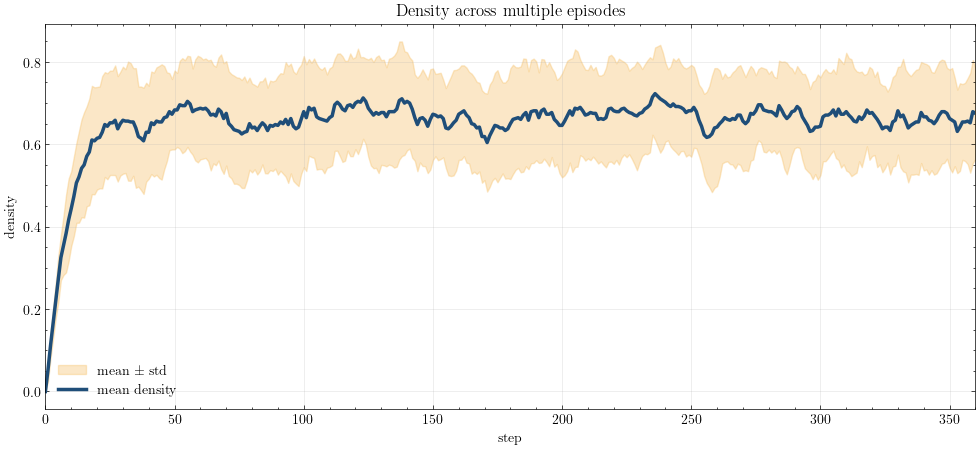

In [9]:
figure, axis = plt.subplots(figsize=(12, 5))
plot_episode_series_observer(observer=multi_density_observer, ax=axis)
plt.show()